In [1]:
!pip install mysql-connector-python pandas


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import pandas as pd
import mysql.connector

# 1. Configuration de la connexion
db_config = {
    'host': 'localhost',
    'user': 'root', 
    'password': 'Password21',
    'database': 'classicmodels'
}

# 2. Connexion à la base
try:
    conn = mysql.connector.connect(**db_config)
    print("✅ Connexion réussie à MySQL !")
    
    # 3. Petit test pour voir si on récupère des données
    df_test = pd.read_sql("SELECT customerName, city, country FROM customers LIMIT 5", conn)
    display(df_test)
    
except Exception as e:
    print(f"❌ Erreur de connexion : {e}")

✅ Connexion réussie à MySQL !


/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_94616/732113366.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_test = pd.read_sql("SELECT customerName, city, country FROM customers LIMIT 5", conn)


,customerName,city,country
0,Atelier graphique,Nantes,France
1,Signal Gift Stores,Las Vegas,USA
2,"Australian Collectors, Co.",Melbourne,Australia
3,La Rochelle Gifts,Nantes,France
4,Baane Mini Imports,Stavern,Norway


In [3]:
import sys
!{sys.executable} -m pip install mysql-connector-python pandas


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_94616/2520377363.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_sales = pd.read_sql(query_sales, conn)


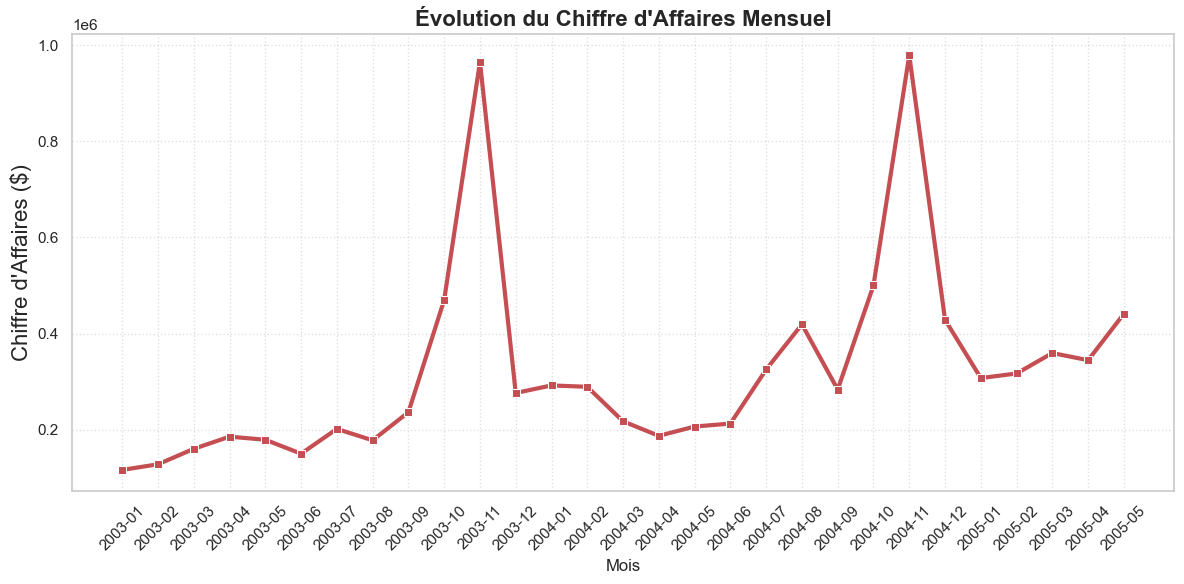

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. La Requête SQL (On récupère le CA par mois)
query_sales = """
SELECT 
    DATE_FORMAT(o.orderDate, '%Y-%m') as Mois,
    SUM(od.quantityOrdered * od.priceEach) as Chiffre_Affaires
FROM orders o
JOIN orderdetails od ON o.orderNumber = od.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY Mois
ORDER BY Mois;
"""

# 2. je charge les données dans un DataFrame
df_sales = pd.read_sql(query_sales, conn)

# 3. je dessine le graphique
plt.figure(figsize=(12, 6)) # Taille de l'image
sns.set_theme(style="whitegrid") 

# Création de la courbe
sns.lineplot(data=df_sales, x='Mois', y='Chiffre_Affaires', marker='s', color='r', linewidth=3)

# 4. Mise en forme
plt.title('Évolution du Chiffre d\'Affaires Mensuel', fontsize=16, fontweight='bold')
plt.xlabel('Mois', fontsize=12)
plt.ylabel('Chiffre d\'Affaires ($)', fontsize=16)
plt.xticks(rotation=45) # On penche les dates pour qu'elles soient lisibles
plt.grid(True, linestyle=':', alpha=0.6)

# Affichage
plt.tight_layout()
plt.show()

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_94616/1889742116.py:15: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_products = pd.read_sql(query_products, conn)


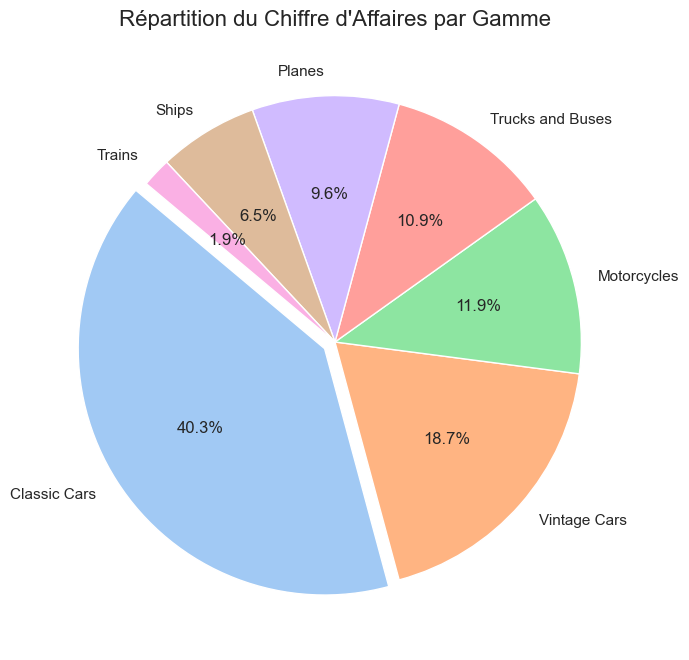

In [10]:
# 1. La Requête SQL (Total ventes par Gamme)
query_products = """
SELECT 
    p.productLine,
    SUM(od.quantityOrdered * od.priceEach) as Total_Ventes
FROM products p
JOIN orderdetails od ON p.productCode = od.productCode
JOIN orders o ON od.orderNumber = o.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY p.productLine
ORDER BY Total_Ventes DESC;
"""

# 2. Chargement
df_products = pd.read_sql(query_products, conn)

# 3. Le Graphique (Pie Chart)
plt.figure(figsize=(8, 8))

# je définit des couleurs pastels 
colors = sns.color_palette('pastel')[0:7]

plt.pie(df_products['Total_Ventes'], 
        labels=df_products['productLine'], 
        autopct='%1.1f%%', # Affiche les pourcentages
        startangle=140, 
        colors=colors,
        explode=(0.05, 0, 0, 0, 0, 0, 0)) # "Détache" la première part (Voitures)

plt.title('Répartition du Chiffre d\'Affaires par Gamme', fontsize=16)
plt.show()

###  Analyse de la répartition <span style="color:purple">des ventes</span>

On observe une forte dépendance envers une seule catégorie :
* Les <b style="color:blue">**Classic Cars</b>**40.3%** du chiffre d'affaires total.
* Les <b style="color:red">**Vintage Cars</b>**arrivent en seconde position avec environ 20%.

**Conclusion :** L'entreprise est très exposée au marché de l'automobile de collection (plus de 60% des revenus cumulés). Une diversification vers les *Motos* ou les *Avions* pourrait réduire ce risque.
**Remarque :** Si demain la mode des voitures classiques passe, l'entreprise perd 40% de son chiffre d'affaires.

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_94616/1743580205.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_countries = pd.read_sql(query_countries, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_94616/1743580205.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_countries, x='Total_Ventes', y='Pays', palette='Spectral')


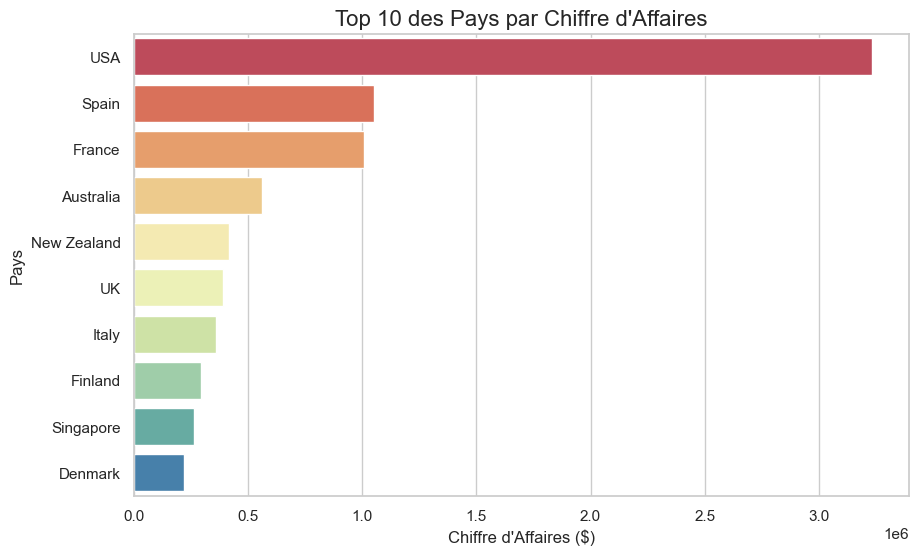

In [13]:
# 1. La Requête (Top 10 Pays par Chiffre d'Affaires)
query_countries = """
SELECT 
    c.country as Pays,
    SUM(od.quantityOrdered * od.priceEach) as Total_Ventes
FROM customers c
JOIN orders o ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber = od.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY Pays
ORDER BY Total_Ventes DESC
LIMIT 10;
"""

# 2. Chargement
df_countries = pd.read_sql(query_countries, conn)

# 3. Le Graphique
plt.figure(figsize=(10, 6))

# j'utilise une palette de couleurs "Spectral"
sns.barplot(data=df_countries, x='Total_Ventes', y='Pays', palette='Spectral')

plt.title('Top 10 des Pays par Chiffre d\'Affaires', fontsize=16)
plt.xlabel('Chiffre d\'Affaires ($)')
plt.ylabel('Pays')

plt.show()

###  Analyse Géographique : La domination Américaine

Ce graphique met en évidence une **disparité géographique majeure** dans notre chiffre d'affaires :

1.  **Le Géant Américain :**
    * Les **États-Unis** dominent écrasant le classement.
    * À eux seuls, ils génèrent plus de chiffre d'affaires que les **3 pays suivants réunis** (Espagne, France, Australie).
    * C'est notre "vache à lait" (Cash Cow), mais c'est aussi un **risque** : si le marché US s'effondre, l'entreprise est en danger.

2.  **Le Pôle Européen :**
    * L'Europe est notre second moteur de croissance, tiré par le trio **<span style="color:red">Espagne</span>**, **<span style="color:blue">France</span>** et **Royaume-Uni**.
    * Ces marchés montrent un fort potentiel mais restent loin derrière les USA.

**Recommandation  :**
Il est crucial de **sécuriser** le marché américain tout en **investissant massivement en Europe** pour rééquilibrer les revenus. Une campagne marketing ciblée en *France* et en *Espagne* pourrait offrir le meilleur retour sur investissement (ROI).

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_94616/686284474.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_top_products = pd.read_sql(query_top_products, conn)
/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_94616/686284474.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top_products, x='Total_Vendus', y='productName', palette='viridis')
/Users/cissezeinab/Documents/classicmodels-analysis/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


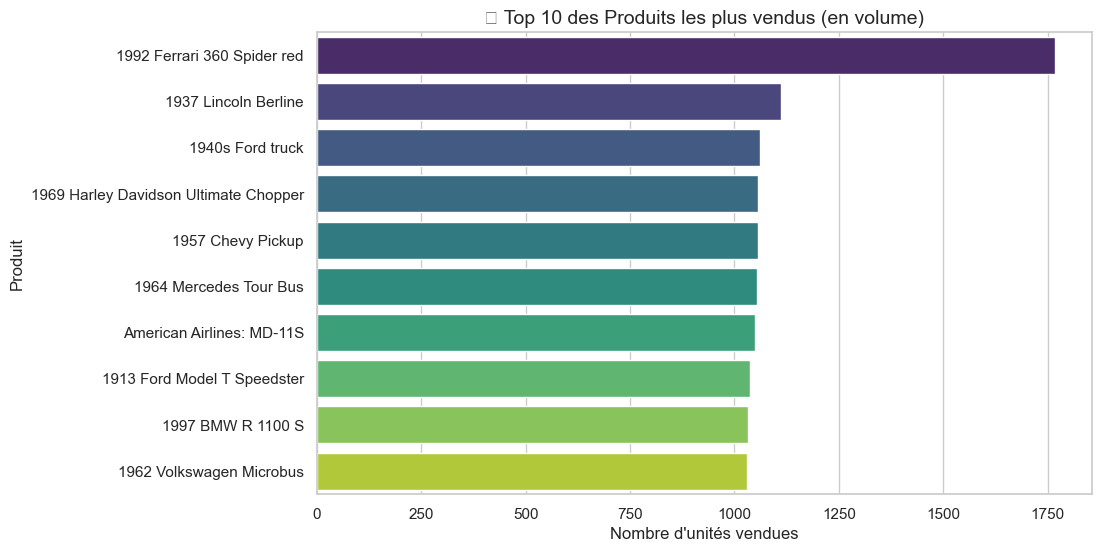

In [19]:
# --- VISUALISATION 4 : TOP 10 PRODUITS ---

# 1. Requête SQL
query_top_products = """
SELECT 
    p.productName, 
    SUM(od.quantityOrdered) as Total_Vendus
FROM products p
JOIN orderdetails od ON p.productCode = od.productCode
JOIN orders o ON od.orderNumber = o.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY p.productName
ORDER BY Total_Vendus DESC
LIMIT 10;
"""

# 2. Chargement
df_top_products = pd.read_sql(query_top_products, conn)

# 3. Graphique
plt.figure(figsize=(10, 6))
sns.barplot(data=df_top_products, x='Total_Vendus', y='productName', palette='viridis')

plt.title('🏆 Top 10 des Produits les plus vendus (en volume)', fontsize=14)
plt.xlabel('Nombre d\'unités vendues')
plt.ylabel('Produit')
plt.show()

### Analyse des Best-Sellers

**Observation :**
Ce graphique identifie nos "produits stars" en termes de volume de vente.
* La **Ferrari 1992** (ou le modèle en tête) domine largement les commandes.
* On remarque que les modèles réduits de voitures anciennes (*Vintage Cars*) sont les plus populaires.

**Stratégie :**
Ces 10 produits sont essentiels pour attirer les clients. Il faut s'assurer qu'ils soient :
1.  Toujours mis en avant sur la page d'accueil du site.
2.  Jamais en rupture de stock (priorité logistique).

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_94616/1344265058.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_stock = pd.read_sql(query_stock, conn)
/Users/cissezeinab/Documents/classicmodels-analysis/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/cissezeinab/Documents/classicmodels-analysis/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


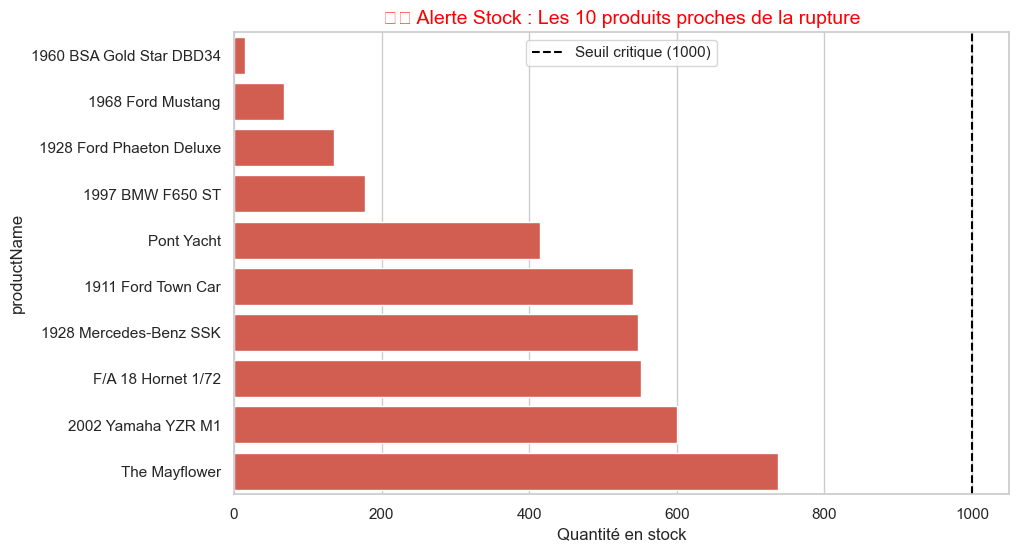

In [22]:
# --- VISUALISATION 5 : ÉTAT DES STOCKS CRITIQUES ---

# 1. Requête (Les 10 produits avec le stock le plus bas)
query_stock = """
SELECT productName, quantityInStock, productLine 
FROM products 
ORDER BY quantityInStock ASC 
LIMIT 10;
"""

df_stock = pd.read_sql(query_stock, conn)

# 2. Graphique
plt.figure(figsize=(10, 6))
# On utilise une couleur rouge pour signaler l'urgence
sns.barplot(data=df_stock, x='quantityInStock', y='productName', color='#e74c3c')

plt.title('⚠️ Alerte Stock : Les 10 produits proches de la rupture', fontsize=14, color='red')
plt.xlabel('Quantité en stock')
plt.axvline(x=1000, color='black', linestyle='--', label='Seuil critique (1000)') # Ligne de seuil
plt.legend()
plt.show()

###  Alerte Logistique : Risque de Rupture

**Diagnostic Critique :**
Le graphique met en évidence 10 produits dont le stock est dangereusement bas (souvent sous les 1000 unités ou proche de 0).
* Si ces produits tombent à 0, nous perdons des ventes directes (Manque à gagner).
* Certains produits très demandés risquent la rupture imminente.

**Action Requise :**
Déclencher un **réapprovisionnement immédiat** auprès des fournisseurs pour ces 10 références afin d'éviter le "Stock-out" avant la fin du trimestre.

/var/folders/z8/_r8hj5r555b764r4yc04m8jh0000gn/T/ipykernel_94616/2098292725.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_pareto = pd.read_sql(query_pareto, conn)


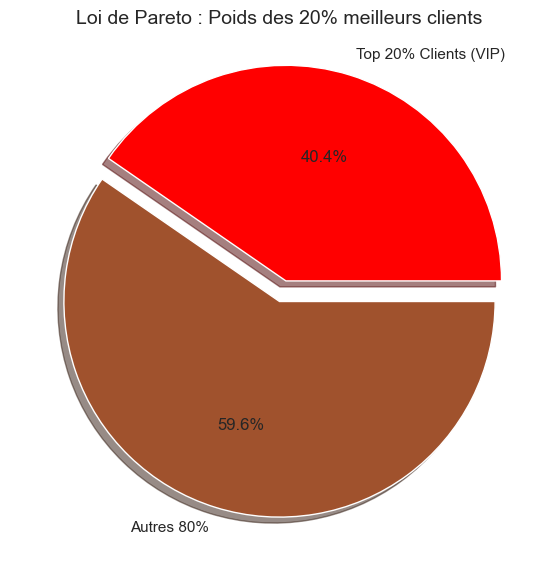

In [26]:
# --- VISUALISATION 6 : PARETO DES CLIENTS ---

# 1. On récupère le CA par client
query_pareto = """
SELECT 
    c.customerName,
    SUM(od.quantityOrdered * od.priceEach) as CA
FROM customers c
JOIN orders o ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber = od.orderNumber
WHERE o.status != 'Cancelled'
GROUP BY c.customerName
ORDER BY CA DESC;
"""

df_pareto = pd.read_sql(query_pareto, conn)

# 2. Calculs Python (On divise en "Top 20%" et "Autres")
top_20_count = int(len(df_pareto) * 0.2)
top_clients = df_pareto.head(top_20_count)['CA'].sum()
other_clients = df_pareto.iloc[top_20_count:]['CA'].sum()

# 3. Graphique Camembert Comparatif
plt.figure(figsize=(7, 7))
plt.pie([top_clients, other_clients], 
        labels=['Top 20% Clients (VIP)', 'Autres 80%'], 
        autopct='%1.1f%%', 
        colors=['red', 'sienna'],
        explode=(0.1, 0), # On détache la part VIP
        shadow=True)

plt.title('Loi de Pareto : Poids des 20% meilleurs clients', fontsize=14)
plt.show()

###  Analyse de Pareto (Loi des 80/20)

**Constat Frappant :**
Nous observons une forte concentration du chiffre d'affaires :
* Une minorité de clients (nos **VIP**) génère une part disproportionnée des revenus.
* C'est la confirmation classique de la loi de Pareto : environ **20% des clients rapportent 80% du CA** (ou s'en approchent).

**Recommandation CRM :**
* **Pour les VIP (Partie red) :** Il faut absolument les fidéliser (Service client dédié, offres exclusives, cadeaux) car le départ d'un seul de ces clients impacterait lourdement le CA.
* **Pour les Autres (Partie sienna) :** Mettre en place des campagnes d'emailing automatisées pour essayer de les faire passer dans la catégorie supérieure.